<a href="https://colab.research.google.com/github/RajeevKambhatla/longevity-drug-repurposing/blob/main/11_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q rdkit umap-learn
from google.colab import drive
drive.mount('/content/drive')

import json, pandas as pd, numpy as np
from tqdm import tqdm
BASE = '/content/drive/MyDrive/longevity_project'
kd = json.load(open(f'{BASE}/data/processed/known_drugs.json'))
vcap = pd.read_csv(f'{BASE}/data/processed/vcap_sig_info.csv')
genes = pd.read_csv(f'{BASE}/data/raw/GSE92742_Broad_LINCS_gene_info.txt.gz', sep='\t')
bing = genes[genes['pr_is_bing'] == 1]
id_to_symbol = dict(zip(bing['pr_gene_id'].astype(str), bing['pr_gene_symbol']))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 29.1 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
vcap['name'] = vcap['pert_iname'].str.lower()
vcap['is_24h'] = vcap['pert_time'] == 24
pick = vcap.sort_values(['is_24h', 'pert_dose'], ascending=False).groupby('name').head(1)
pick = pick[['name', 'sig_id', 'pert_id', 'pert_iname']].set_index('name')
pick['is_named'] = ~pick['pert_iname'].str.startswith('BRD-')
print(len(pick), 'compounds')

15542 compounds


In [3]:
!wget -nc -P {BASE}/data/raw https://ftp.ncbi.nlm.nih.gov/geo/series/GSE92nnn/GSE92742/suppl/GSE92742_Broad_LINCS_pert_info.txt.gz
pinfo = pd.read_csv(f'{BASE}/data/raw/GSE92742_Broad_LINCS_pert_info.txt.gz', sep='\t')
print(pinfo.columns.tolist())

pinfo = pinfo.drop_duplicates('pert_id').set_index('pert_id')
pick = pick.join(pinfo[['canonical_smiles', 'inchi_key']], on='pert_id')
pick = pick.replace({'canonical_smiles': {'-666': np.nan}, 'inchi_key': {'-666': np.nan}})
print(pick['canonical_smiles'].notna().sum(), 'of', len(pick), 'have a structure')

--2026-10-12 20:03:08--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE92nnn/GSE92742/suppl/GSE92742_Broad_LINCS_pert_info.txt.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.11, 130.14.250.12, 2607:f220:41e:250::12, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.11|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1138509 (1.1M) [application/x-gzip]
Saving to: ‘/content/drive/MyDrive/longevity_project/data/raw/GSE92742_Broad_LINCS_pert_info.txt.gz’

GSE92742_Broad_LINC 100%[===================>]   1.08M  3.49MB/s    in 0.3s    

2026-10-12 20:03:08 (3.49 MB/s) - ‘/content/drive/MyDrive/longevity_project/data/raw/GSE92742_Broad_LINCS_pert_info.txt.gz’ saved [1138509/1138509]

['pert_id', 'pert_iname', 'pert_type', 'is_touchstone', 'inchi_key_prefix', 'inchi_key', 'canonical_smiles', 'pubchem_cid']
15517 of 15542 have a structure


In [4]:
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

fps = np.zeros((len(pick), 2048), dtype=np.uint8)
ok = np.zeros(len(pick), dtype=bool)
for i, smi in enumerate(tqdm(pick['canonical_smiles'])):
    if isinstance(smi, str):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            fps[i] = gen.GetFingerprintAsNumPy(mol)
            ok[i] = True

pick['has_structure'] = ok
fp = pd.DataFrame(fps, index=pick.index, columns=[f'fp_{j}' for j in range(2048)])
fp.to_parquet(f'{BASE}/data/processed/ecfp4.parquet')
pick.to_csv(f'{BASE}/data/processed/compounds.csv')
print(ok.sum(), 'fingerprints built')

100%|██████████| 15542/15542 [00:06<00:00, 2317.40it/s]


15503 fingerprints built


In [5]:
def tanimoto(a, b):
    for d in (a, b):
        if d not in fp.index or not pick.loc[d, 'has_structure']:
            return f'{d} has no structure'
    x, y = fp.loc[a].values.astype(bool), fp.loc[b].values.astype(bool)
    return f'{(x & y).sum() / (x | y).sum():.2f}'

for a, b in [('sirolimus', 'everolimus'), ('sirolimus', 'temsirolimus'),
             ('geldanamycin', 'tanespimycin'), ('sirolimus', 'metformin')]:
    print(f'{a} vs {b}: {tanimoto(a, b)}')

sirolimus vs everolimus: 0.87
sirolimus vs temsirolimus: 0.84
geldanamycin vs tanespimycin: 0.75
sirolimus vs metformin: 0.02


In [6]:
from sklearn.decomposition import PCA

sigs = pd.read_parquet(f'{BASE}/data/processed/vcap_signatures.parquet', columns=list(id_to_symbol))
sigs = sigs.loc[pick['sig_id']]
sigs.index = pick.index

pca = PCA(n_components=100, random_state=0)
X = pca.fit_transform(sigs.values)
cum = pca.explained_variance_ratio_.cumsum()
print(f'Variance captured: 10 components {cum[9]:.0%}, 50 {cum[49]:.0%}, 100 {cum[99]:.0%}')

sigpca = pd.DataFrame(X, index=pick.index, columns=[f'pc_{i}' for i in range(100)]).astype('float32')
sigpca.to_parquet(f'{BASE}/data/processed/signature_pca.parquet')
del sigs

Variance captured: 10 components 34%, 50 52%, 100 62%


In [7]:
from sklearn.metrics.pairwise import cosine_similarity
named = sigpca[pick['is_named']]
sims = pd.Series(cosine_similarity(named.loc[['sirolimus']], named)[0], index=named.index)
print(sims.drop('sirolimus').nlargest(10).round(2))

name
pi-828               0.68
ku-0063794           0.67
ly-294002            0.66
aminopurvalanol-a    0.65
ro-28-1675           0.63
kin001-244           0.62
azd-8055             0.62
tpca-1               0.59
wye-354              0.59
linsitinib           0.59
dtype: float32


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


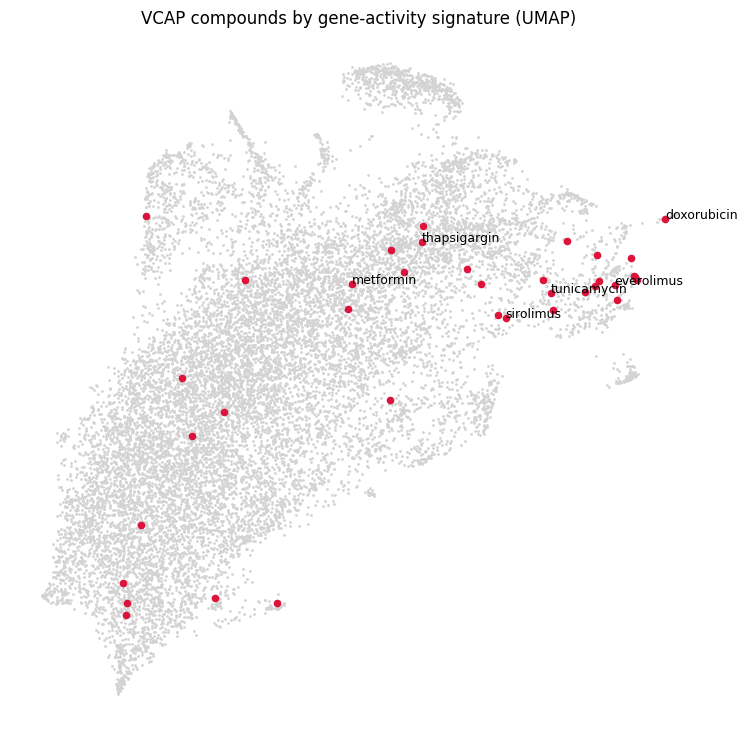

In [8]:
import umap
import matplotlib.pyplot as plt

emb = umap.UMAP(random_state=0).fit_transform(sigpca.iloc[:, :50])
emb = pd.DataFrame(emb, index=sigpca.index, columns=['x', 'y'])

known = {d for k in kd['by_hallmark'].values() for d in k['helpful'] + k['harmful']} & set(emb.index)
plt.figure(figsize=(9, 9))
plt.scatter(emb['x'], emb['y'], s=1, c='lightgray')
plt.scatter(emb.loc[list(known), 'x'], emb.loc[list(known), 'y'], s=20, c='crimson')
for d in ['sirolimus', 'everolimus', 'tunicamycin', 'thapsigargin', 'doxorubicin', 'metformin']:
    if d in emb.index:
        plt.annotate(d, (emb.loc[d, 'x'], emb.loc[d, 'y']), fontsize=9)
plt.title('VCAP compounds by gene-activity signature (UMAP)')
plt.axis('off')
plt.savefig(f'{BASE}/results/umap_signatures.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
BASE = '/content/drive/MyDrive/longevity_project'

compounds = pd.read_csv(f'{BASE}/data/processed/compounds.csv', index_col='name')
sigpca = pd.read_parquet(f'{BASE}/data/processed/signature_pca.parquet')
S = int(compounds['has_structure'].sum())

named = sigpca[compounds.loc[sigpca.index, 'is_named'].values]
sims = pd.Series(cosine_similarity(named.loc[['sirolimus']], named)[0], index=named.index)
neighbors = ', '.join(sims.drop('sirolimus').nlargest(5).index)

try:
    V = f'{cum[99]:.0%}'
except NameError:
    V = '[V]'
    print('Note: Colab has restarted since Step 6, so fill in V from the Step 6 output.\n')

print(f"Built ML features for {len(compounds):,} VCAP compounds: ECFP4 chemical fingerprints for {S:,} "
      f"compounds with structures, and 100 PCA components of the gene-activity signatures ({V} of variance); "
      f"signature neighbors of sirolimus include {neighbors}; UMAP map saved.")

Built ML features for 15,542 VCAP compounds: ECFP4 chemical fingerprints for 15,503 compounds with structures, and 100 PCA components of the gene-activity signatures (62% of variance); signature neighbors of sirolimus include pi-828, ku-0063794, ly-294002, aminopurvalanol-a, ro-28-1675; UMAP map saved.
